# Environment Setup and Library Imports

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import csv
from sklearn.decomposition import PCA
from transformers import CLIPModel
from tqdm import tqdm

from src.model import CLIPForFlickr8k
from src.dataset import create_dataloaders
from src.train import train
from src.inference import run_inference



# Check GPU availability
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

CUDA Available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 8.6 GB


#  Data Loading and Preprocessing Configuration

In [2]:
# Use correct paths (without data/ prefix)
IMAGE_DIR = os.path.abspath('Flickr8k/Images')
CAPTIONS_FILE = os.path.abspath('Flickr8k/captions.txt')
MODEL_PATH = os.path.abspath('models/clip-vit-base-patch32')


# Load CLIP model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CLIPForFlickr8k(clip_model_name=MODEL_PATH, device=device)
processor = model.processor

# Create dataloaders
print("\nCreating dataloaders...")
train_loader, val_loader, test_loader = create_dataloaders(
    IMAGE_DIR, CAPTIONS_FILE, processor, batch_size=32
)


# Show sample batch
batch = next(iter(train_loader))
print(f"\n Sample batch:")
print(f"  Image shape: {batch['image'].shape}")
print(f"  Text shape: {batch['text'].shape}")
print(f"  Caption example: {batch['caption'][0][:100]}...")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Trainable: 10,240,256 / 151,277,313 (6.8%)

Creating dataloaders...
train split: 6472 images
val split: 809 images
test split: 810 images

 Sample batch:
  Image shape: torch.Size([32, 3, 224, 224])
  Text shape: torch.Size([32, 77])
  Caption example: The man is throwing a toy to a brown and black dog in the park ....


#  Dataset Sample Visualization

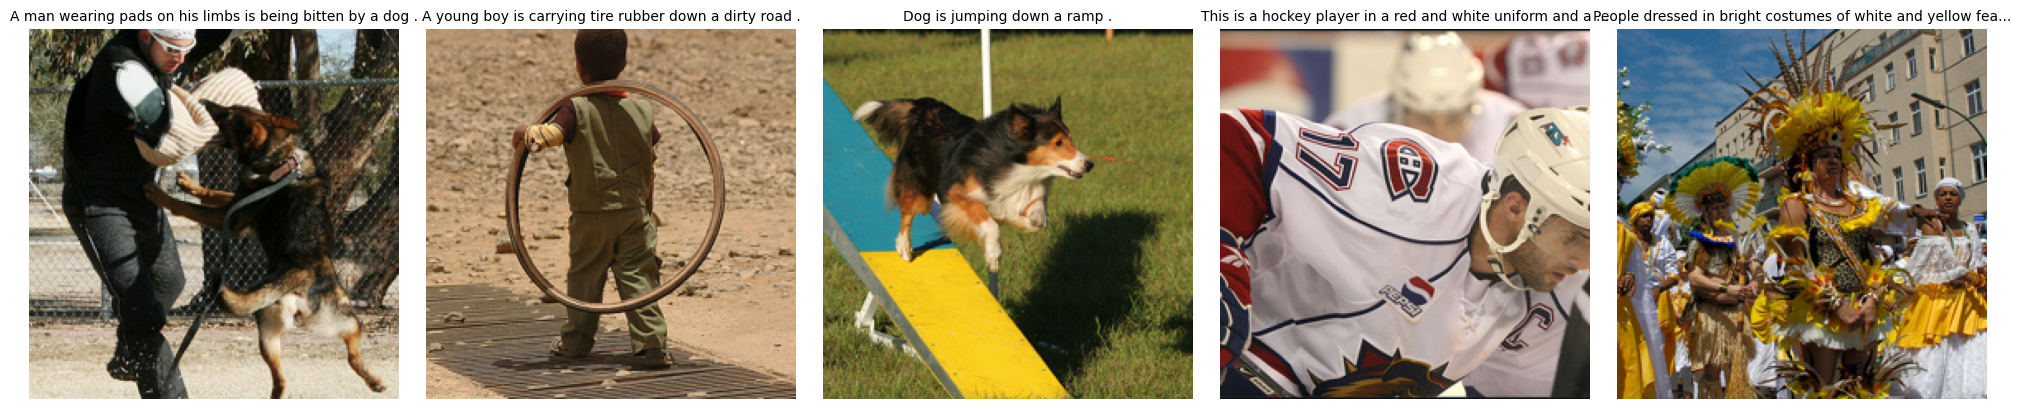

In [10]:
os.makedirs('outputs/results', exist_ok=True)

mean = processor.image_processor.image_mean  
std = processor.image_processor.image_std   

def denormalize_image(tensor):
    tensor = tensor * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return tensor.clamp(0, 1)

def show_samples(dataloader, num_samples=5):
    """Display sample images with their captions"""
    batch = next(iter(dataloader))
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 4))
    
    for i in range(num_samples):
        # Denormalize image tensor
        img_tensor = denormalize_image(batch['image'][i])
        img = img_tensor.permute(1, 2, 0).cpu().numpy()
        
        axes[i].imshow(img)
        # Truncate long captions for display
        caption = batch['caption'][i]
        if len(caption) > 60:
            caption = caption[:57] + '...'
        axes[i].set_title(caption, fontsize=10)
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.savefig('outputs/results/dataset_samples.png', dpi=150, bbox_inches='tight')
    plt.show()


show_samples(train_loader)

# Fine-tuning on Flickr8k Dataset

Starting Fine-tuning
--------------------------------------------------
Optimizing 10,240,256 parameters

Epoch 1/20


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:05<00:00,  4.46it/s]


Train Loss: 0.1814, Val Loss: 0.2505, LR: 9.94e-06
 Best model saved!

Epoch 2/20


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:03<00:00,  7.57it/s]


Train Loss: 0.1449, Val Loss: 0.2420, LR: 9.78e-06
 Best model saved!

Epoch 3/20


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:03<00:00,  7.55it/s]


... (31 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:03<00:00,  7.62it/s]


Train Loss: 0.0682, Val Loss: 0.2198, LR: 1.06e-06

Epoch 20/20


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:03<00:00,  7.60it/s]


Train Loss: 0.0676, Val Loss: 0.2490, LR: 1.00e-06


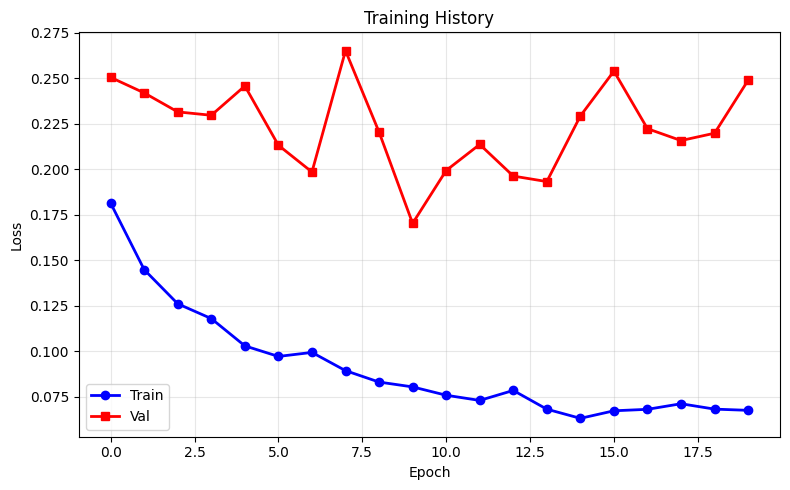


 Best: Epoch 10, Val Loss: 0.1703


In [4]:
os.makedirs('outputs/checkpoints', exist_ok=True)

print("Starting Fine-tuning")
print("-" * 50)

train_losses, val_losses = train(
    model, train_loader, val_loader,
    num_epochs=20,
    lr=1e-5,
    device=device
)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(train_losses, 'b-o', label='Train', linewidth=2)
plt.plot(val_losses, 'r-s', label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training History')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/results/training_history.png', dpi=150)
plt.show()

best_epoch = val_losses.index(min(val_losses)) + 1
print(f"\n Best: Epoch {best_epoch}, Val Loss: {min(val_losses):.4f}")

#  Model Inference

Loading best model...
 Loaded from epoch 10, Val Loss: 0.1703

------------------------------------------------------------
Test Image: 438639005_208bc59b0b.jpg
------------------------------------------------------------
Ground Truth Captions:
  • A boy in red and a girl pink are walking through a low cut field .
  • The little boy and little girl are walking side by side .
  • Two small children walk away in a field .
  • Two small children walking in a field .
  • Two young children are walking across an open field .


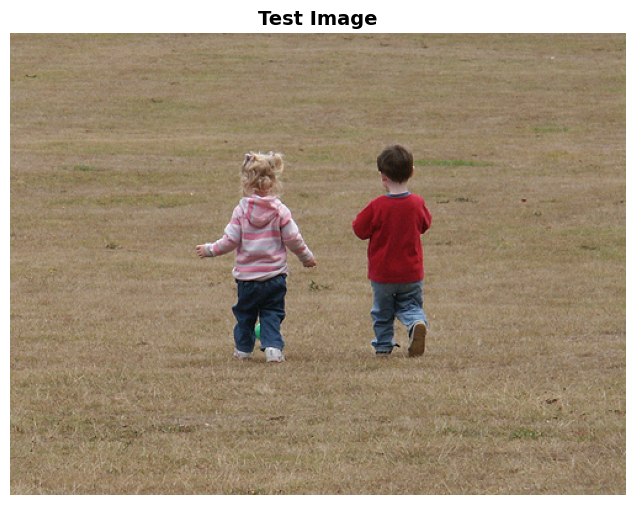


Searching among 105 captions...

------------------------------------------------------------
 Top-5 Retrieved Captions:
  1. [33.5] (60.1%) A boy in red and a girl pink are walking through a low cut field .  GROUND TRUTH
  2. [32.3] (17.0%) Two young children are walking across an open field .  GROUND TRUTH
  3. [31.9] (12.1%) Two small children walking in a field .  GROUND TRUTH
  4. [31.8] (10.4%) Two small children walk away in a field .  GROUND TRUTH
  5. [28.5] (0.4%) The little boy and little girl are walking side by side .  GROUND TRUTH

------------------------------------------------------------
 Recall@5: 5/5 ground truth captions found
   Best score: 33.5


In [6]:
#Loading best model
checkpoint = torch.load('outputs/checkpoints/best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])


# Run inference
top5, captions, ground_truth = run_inference(
    model=model,
    test_loader=test_loader,
    IMAGE_DIR=IMAGE_DIR,
    CAPTIONS_FILE=CAPTIONS_FILE,
    device=device
)

#  Embedding Space Visualization with PCA

Collected 160 pairs
Feature dimension: 512


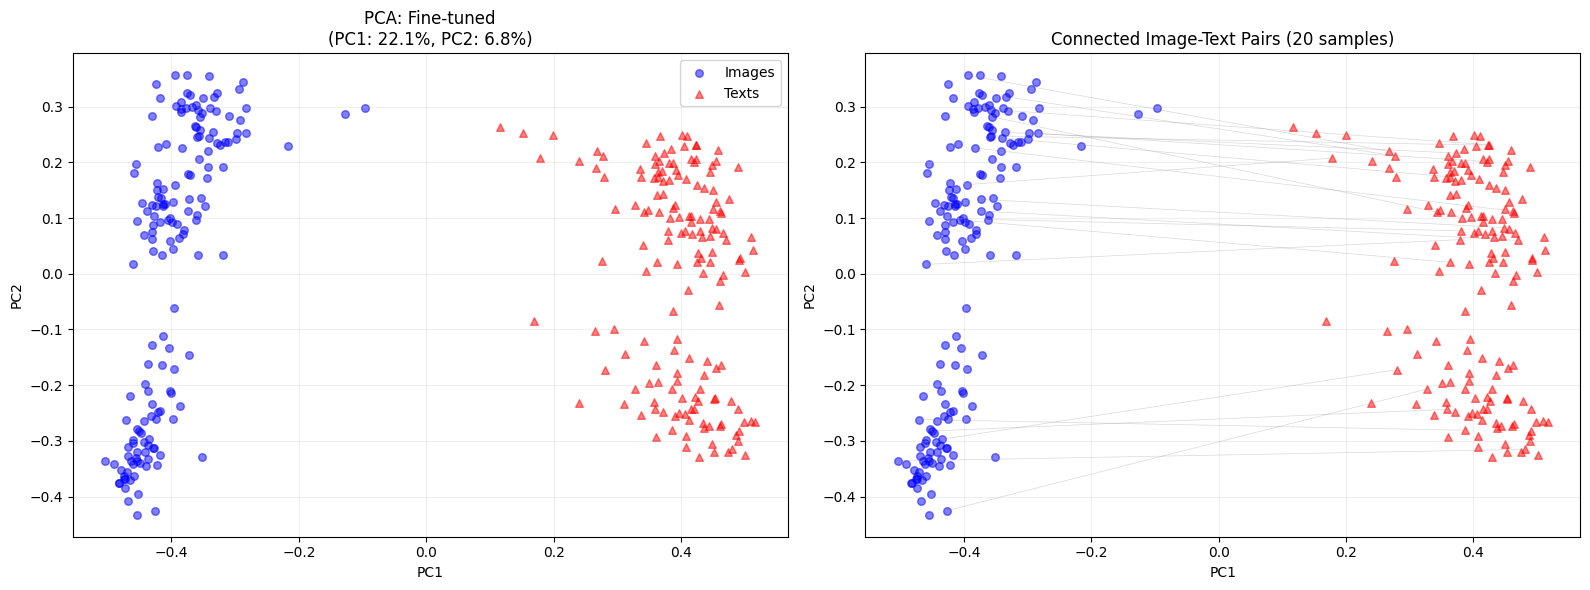

EMBEDDING ANALYSIS - Fine-tuned
--------------------------------------------------
PCA Variance: PC1=22.1%, PC2=6.8%
Total 2D variance: 29.0%
Modality Gap: 0.796
Avg pair distance: 0.802 ± 0.096


In [4]:
os.makedirs('outputs/results', exist_ok=True)

#Loading fine-tuned model for visualization
checkpoint = torch.load('outputs/checkpoints/best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
model_type = "Fine-tuned"

# Collect embeddings
image_features_list = []
text_features_list = []

with torch.no_grad():
    for i, batch in enumerate(test_loader):
        if i >= 5:
            break
        
        images = batch['image'].to(device)
        texts = batch['text'].to(device)
        
        # Wrapper model forward
        _, _, img_feat, txt_feat = model(images, texts)
        
        image_features_list.append(img_feat.cpu().numpy())
        text_features_list.append(txt_feat.cpu().numpy())

image_features = np.vstack(image_features_list)
text_features = np.vstack(text_features_list)
combined = np.vstack([image_features, text_features])

n = len(image_features)
print(f"Collected {n} pairs")
print(f"Feature dimension: {image_features.shape[1]}")

# PCA
pca = PCA(n_components=2)
reduced = pca.fit_transform(combined)
images_pca = reduced[:n]
texts_pca = reduced[n:]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All points
axes[0].scatter(images_pca[:, 0], images_pca[:, 1], c='blue', label='Images', alpha=0.5, s=30)
axes[0].scatter(texts_pca[:, 0], texts_pca[:, 1], c='red', label='Texts', alpha=0.5, s=30, marker='^')
axes[0].set_title(f'PCA: {model_type}\n(PC1: {pca.explained_variance_ratio_[0]:.1%}, PC2: {pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()
axes[0].grid(True, alpha=0.2)

# Connected pairs
sample_idx = np.random.choice(n, min(20, n), replace=False)
for idx in sample_idx:
    axes[1].plot([images_pca[idx, 0], texts_pca[idx, 0]], 
                 [images_pca[idx, 1], texts_pca[idx, 1]], 'gray', alpha=0.3, linewidth=0.5)
axes[1].scatter(images_pca[:, 0], images_pca[:, 1], c='blue', alpha=0.5, s=30)
axes[1].scatter(texts_pca[:, 0], texts_pca[:, 1], c='red', alpha=0.5, s=30, marker='^')
axes[1].set_title('Connected Image-Text Pairs (20 samples)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('outputs/results/embeddings_pca.png', dpi=150)
plt.show()

# Stats
distances = [np.linalg.norm(images_pca[i] - texts_pca[i]) for i in range(n)]
image_center = np.mean(images_pca, axis=0)
text_center = np.mean(texts_pca, axis=0)
gap = np.linalg.norm(image_center - text_center)


print(f"EMBEDDING ANALYSIS - {model_type}")
print(f"{'-'*50}")
print(f"PCA Variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}")
print(f"Total 2D variance: {sum(pca.explained_variance_ratio_):.1%}")
print(f"Modality Gap: {gap:.3f}")
print(f"Avg pair distance: {np.mean(distances):.3f} ± {np.std(distances):.3f}")

# Comparison with Original CLIP with Test Set

In [5]:
# Fix randomness
np.random.seed(42)

# Load models
print("\nLoading models...")
checkpoint = torch.load('outputs/checkpoints/best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

original_model = CLIPModel.from_pretrained(MODEL_PATH, local_files_only=True).to(device)
original_model.eval()

# Load ALL captions
image_to_captions = {}
all_captions_pool = []

with open(CAPTIONS_FILE, 'r') as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        img_name = row[0].strip()
        caption = row[1].strip()
        
        if img_name not in image_to_captions:
            image_to_captions[img_name] = []
        image_to_captions[img_name].append(caption)
        all_captions_pool.append(caption)

# ==========================================
# Pre-generate random captions
# ==========================================
print("Pre-generating random captions (fixed with seed=42)...")

test_image_names = test_loader.dataset.images
print(f"Test images: {len(test_image_names)}")

fixed_random_captions = {}
for img_name in test_image_names:
    gt_caps = image_to_captions[img_name]
    # Pick 95 random captions that are NOT this image's GT
    pool = [c for c in all_captions_pool if c not in gt_caps]
    random_caps = np.random.choice(pool, size=95, replace=False).tolist()
    fixed_random_captions[img_name] = random_caps

print(f"Generated fixed captions for {len(fixed_random_captions)} images")

# ==========================================
# Evaluation Function
# ==========================================
def evaluate_model_fixed(model_to_eval, is_original=False):
    correct = 0
    total = 0
    
    for batch in tqdm(test_loader, desc='Evaluating'):
        images = batch['image'].to(device)
        image_names = batch['image_name']
        
        for i in range(len(images)):
            img_name = image_names[i]
            gt_captions = image_to_captions[img_name]
            image_tensor = images[i:i+1]
            
            # Use pre-generated fixed captions
            random_caps = fixed_random_captions[img_name]
            all_caps = gt_captions + random_caps
            gt_indices = list(range(5))
            
            text_inputs = processor(
                text=all_caps,
                return_tensors='pt',
                padding=True,
                truncation=True,
                max_length=77
            )['input_ids'].to(device)
            
            with torch.no_grad():
                if is_original:
                    img_feat = model_to_eval.get_image_features(pixel_values=image_tensor)
                    if hasattr(img_feat, 'pooler_output'):
                        img_feat = img_feat.pooler_output
                    img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
                    
                    txt_feat = model_to_eval.get_text_features(input_ids=text_inputs)
                    if hasattr(txt_feat, 'pooler_output'):
                        txt_feat = txt_feat.pooler_output
                    txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
                    
                    logit_scale = model_to_eval.logit_scale.exp()
                    similarities = (logit_scale * img_feat @ txt_feat.T).squeeze()
                else:
                    _, _, img_feat, txt_feat = model_to_eval(image_tensor, text_inputs)
                    similarities = (100.0 * img_feat @ txt_feat.T).squeeze()
                
                best_idx = similarities.argmax().item()
                if best_idx in gt_indices:
                    correct += 1
                
                total += 1
    
    return correct, total

# ==========================================
# Run Evaluation
# ==========================================
print(f"\nEvaluating Fine-tuned model...")
ft_correct, ft_total = evaluate_model_fixed(model, is_original=False)

print(f"\nEvaluating Original CLIP...")
orig_correct, orig_total = evaluate_model_fixed(original_model, is_original=True)

# ==========================================
# Results
# ==========================================
ft_acc = ft_correct / ft_total * 100
orig_acc = orig_correct / orig_total * 100


print(f"Test images: {ft_total}")
print(f"Setup: 5 GT + 95 random captions per image")
print(f"")
print(f"Fine-tuned: {ft_acc:.1f}% ({ft_correct}/{ft_total})")
print(f"Original:   {orig_acc:.1f}% ({orig_correct}/{orig_total})")
print(f"Difference: {ft_acc - orig_acc:+.1f}%")



Loading models...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Pre-generating random captions (fixed with seed=42)...
Test images: 810
Generated fixed captions for 810 images

Evaluating Fine-tuned model...


Evaluating: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [01:33<00:00,  3.61s/it]



Evaluating Original CLIP...


Evaluating: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:41<00:00,  1.58s/it]

Test images: 810
Setup: 5 GT + 95 random captions per image

Fine-tuned: 98.6% (799/810)
Original:   97.4% (789/810)
Difference: +1.2%
